# Preprocessing Dataset Ulasan E-Commerce Indonesia

Nama : T. Makmun
NIM : 24146096
Mata Kuliah : Natural Language Processing

## Tujuan

Notebook ini bertujuan melakukan preprocessing terhadap dataset ulasan e-commerce berbahasa Indonesia. Tahapan preprocessing meliputi case folding, cleaning, tokenisasi, stopword removal, dan stemming sebelum data digunakan pada proses analisis sentimen.

## Persiapan: Import Library

Import library yang diperlukan untuk membaca dataset, mengolah data teks, melakukan preprocessing, dan menampilkan hasil analisis.

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

from datasets import load_dataset

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [2]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## 1. Dataset

Dataset yang digunakan adalah dataset ulasan e-commerce berbahasa Indonesia dari Hugging Face: **dipawidia/ecommerce-product-reviews-sentiment**.

In [3]:
dataset = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")

In [4]:
dataset

DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})

In [5]:
df = dataset["train"].to_pandas()

In [6]:
df.head()

,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


## 2. Informasi Dataset

Menampilkan informasi dataset, meliputi jumlah data, kolom, dan distribusi label sentimen.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     11606 non-null  str  
 1   translate  11606 non-null  str  
 2   sentimen   11606 non-null  int64
dtypes: int64(1), str(2)
memory usage: 2.6 MB


In [8]:
print("Jumlah Data  :", len(df))
print("Jumlah Kolom :", len(df.columns))
print("Nama Kolom   :", list(df.columns))

print("\nJumlah Data Kosong :")
print(df.isnull().sum())

Jumlah Data  : 11606
Jumlah Kolom : 3
Nama Kolom   : ['review', 'translate', 'sentimen']

Jumlah Data Kosong :
review       0
translate    0
sentimen     0
dtype: int64


In [9]:
print("=" * 40)
print("Distribusi Label Sentimen")
print("=" * 40)

distribusi = df["sentimen"].value_counts().sort_index()
persentase = (df["sentimen"].value_counts(normalize=True).sort_index() * 100).round(2)

print(pd.DataFrame({"Jumlah": distribusi, "Persentase (%)": persentase}))

Distribusi Label Sentimen
          Jumlah  Persentase (%)
sentimen                        
0           5803            50.0
1           5803            50.0


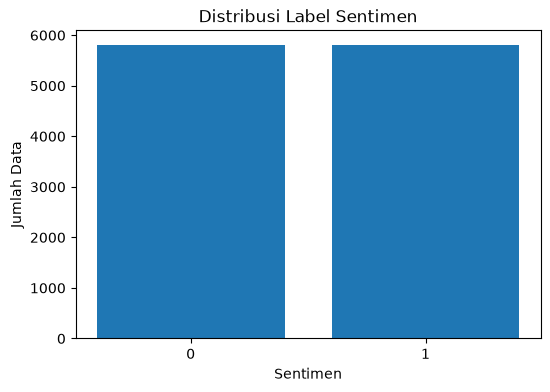

In [10]:
plt.figure(figsize=(6, 4))
plt.bar(distribusi.index.astype(str), distribusi.values)

plt.title("Distribusi Label Sentimen")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Data")

plt.show()

**Catatan label:** dataset card di Hugging Face tidak menjelaskan arti label `0` dan `1`. Berdasarkan contoh data, label `1` umumnya berisi ulasan positif dan label `0` ulasan negatif, namun sebagian label tampak tidak konsisten dengan isi ulasan. Beberapa contoh per label ditampilkan di bawah ini untuk pengecekan.

In [11]:
for label in sorted(df["sentimen"].unique()):
    print(f"===== Contoh ulasan dengan label {label} =====")
    for teks in df[df["sentimen"] == label]["review"].head(3):
        print("-", teks)
    print()

===== Contoh ulasan dengan label 0 =====
- Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
- kondisi dus robek2, tolong di perhatikan lagi
- Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(

===== Contoh ulasan dengan label 1 =====
- Good. Mudah-mudahan awet. Makasih 
- Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sanagt cepat, recommended seller.
- terimakasih banyak ka ya, barang sudah diterima dengan baik. sukses terus ka



## 3. Preprocessing Teks

Preprocessing dilakukan secara bertahap: case folding, cleaning, tokenisasi, stopword removal, dan stemming. Setiap tahap dibuat dalam satu fungsi.

### 3.1 Case Folding

Mengubah teks menjadi huruf kecil.

In [12]:
def case_folding(text):
    return text.lower()

### 3.2 Cleaning

Menghapus URL, angka, tanda baca, dan karakter khusus (termasuk emoji). Karakter yang dihapus diganti spasi agar kata tidak menyatu (misalnya `bagus,tapi` menjadi `bagus tapi`), lalu spasi berlebih dirapikan.

In [13]:
def cleaning(text):

    # Menghapus URL
    text = re.sub(r'http\S+|www\.\S+', ' ', text)

    # Menghapus angka
    text = re.sub(r'\d+', ' ', text)

    # Menghapus tanda baca dan karakter khusus (hanya huruf a-z dan spasi yang dipertahankan)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Menghapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

### 3.3 Tokenisasi

Memisahkan teks menjadi kata.

In [14]:
def tokenizing(text):
    return word_tokenize(text)

### 3.4 Stopword Removal

Menghapus kata yang tidak penting menggunakan daftar stopword bahasa Indonesia dari NLTK, dengan dua penyesuaian:

- Kata negasi (*tidak*, *bukan*, dll.) **dipertahankan**, karena penghapusannya dapat mengubah makna sentimen (misalnya "tidak bagus" menjadi "bagus").
- Kata tidak baku yang sering muncul pada ulasan (misalnya *yg*, *sy*, *tp*) ditambahkan sebagai stopword.

In [15]:
stop_words = set(stopwords.words('indonesian'))

# Kata negasi dipertahankan karena penting untuk sentimen
negasi = {'tidak', 'tak', 'bukan', 'belum', 'jangan', 'kurang'}
print("Negasi yang ada di daftar stopword NLTK :", sorted(negasi & stop_words))
stop_words = stop_words - negasi

# Kata tidak baku yang sering muncul pada ulasan
stop_tambahan = {'yg', 'sy', 'lg', 'tp', 'ga', 'gak', 'nya', 'dgn', 'utk', 'krn', 'dg', 'aja'}
stop_words = stop_words | stop_tambahan

print("Jumlah stopword yang digunakan          :", len(stop_words))

Negasi yang ada di daftar stopword NLTK : ['belum', 'bukan', 'jangan', 'kurang', 'tak', 'tidak']
Jumlah stopword yang digunakan          : 763


In [16]:
def stopword_removal(tokens):
    hasil = []

    for kata in tokens:
        # Kata dibuang jika stopword atau hanya satu huruf
        if kata not in stop_words and len(kata) > 1:
            hasil.append(kata)

    return hasil

### 3.5 Stemming

Mengubah kata menjadi bentuk dasar menggunakan Sastrawi. Hasil stemming disimpan dalam cache agar kata yang sama tidak diproses berulang kali.

In [17]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [18]:
cache_stem = {}

def stemming(tokens):
    hasil = []

    for kata in tokens:
        if kata not in cache_stem:
            cache_stem[kata] = stemmer.stem(kata)
        hasil.append(cache_stem[kata])

    return hasil

### 3.6 Contoh Setiap Tahap

Hasil setiap tahap pada satu ulasan.

In [19]:
contoh = df["review"][0]

hasil_case = case_folding(contoh)
hasil_clean = cleaning(hasil_case)
hasil_token = tokenizing(hasil_clean)
hasil_stop = stopword_removal(hasil_token)
hasil_stem = stemming(hasil_stop)

print("Teks asli      :", contoh)
print()
print("Case folding   :", hasil_case)
print()
print("Cleaning       :", hasil_clean)
print()
print("Tokenisasi     :", hasil_token)
print()
print("Stopword       :", hasil_stop)
print()
print("Stemming       :", hasil_stem)

Teks asli      : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala

Case folding   : suara dan mic puas. hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala

Cleaning       : suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala

Tokenisasi     : ['suara', 'dan', 'mic', 'puas', 'hanya', 'saya', 'pesan', 'yg', 'nyala', 'dan', 'sudah', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'datang', 'ga', 'nyala']

Stopword       : ['suara', 'mic', 'puas', 'pesan', 'nyala', 'pastikan', 'klik', 'nyala', 'nyala']

Stemming       : ['suara', 'mic', 'puas', 'pesan', 'nyala', 'pasti', 'klik', 'nyala', 'nyala']


### 3.7 Preprocessing pada Seluruh Dataset

Seluruh tahapan dijalankan pada kolom `review`. Kolom `tokens` berisi list kata, dan kolom `hasil_preprocessing` berisi kalimat hasil penggabungan kata. Proses stemming pada seluruh data dapat memerlukan beberapa menit.

In [20]:
df["tokens"] = (
    df["review"]
    .apply(case_folding)
    .apply(cleaning)
    .apply(tokenizing)
    .apply(stopword_removal)
    .apply(stemming)
)

df["hasil_preprocessing"] = df["tokens"].apply(" ".join)

In [21]:
# Mengecek ulasan yang menjadi kosong setelah preprocessing
kosong = (df["hasil_preprocessing"].str.strip() == "").sum()

print("Jumlah ulasan kosong setelah preprocessing :", kosong)

Jumlah ulasan kosong setelah preprocessing : 19


## 4. Contoh Teks Sebelum dan Sesudah Preprocessing

Berikut 10 contoh ulasan sebelum dan sesudah preprocessing.

In [24]:
for i in range(10):
    print(f"[{i + 1}]")
    print("Sebelum :", df["review"][i])
    print("Sesudah :", df["hasil_preprocessing"][i])
    print()

[1]
Sebelum : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Sesudah : suara mic puas pesan nyala pasti klik nyala nyala

[2]
Sebelum : Good. Mudah-mudahan awet. Makasih 
Sesudah : good mudah mudah awet makasih

[3]
Sebelum : kondisi dus robek2, tolong di perhatikan lagi
Sesudah : kondisi dus robek tolong perhati

[4]
Sebelum : Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo buat kado gabisa nitip pake kartu ucapan atau dibungkus pake kertas kado :(
Sesudah : kualitas produk harga jangkau kirim cepet banget udh order oke sayang klo kado gabisa nitip pake kartu ucap bungkus pake kertas kado

[5]
Sebelum : Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit
Sesudah : overall bagus tombol fungsi packaging kurang penyot robek

[6]
Sebelum : Produk ini original, Dan kualitasnya sangat baik. kecepatan pengiriman sana

## 5. Pengaruh Preprocessing terhadap Kualitas Data Teks

Untuk melihat pengaruhnya secara terukur, dibandingkan rata-rata jumlah kata, rata-rata jumlah karakter, dan ukuran vocabulary (jumlah kata unik) sebelum dan sesudah preprocessing.

In [23]:
def jumlah_vocab(kolom):
    return len(set(" ".join(kolom).split()))

# Teks asli dijadikan huruf kecil dulu agar "Bagus" dan "bagus" dihitung sebagai kata yang sama
review_lower = df["review"].str.lower()

ringkasan = pd.DataFrame({
    "Metrik": ["Rata-rata jumlah kata per ulasan",
               "Rata-rata jumlah karakter per ulasan",
               "Ukuran vocabulary (kata unik)"],
    "Sebelum": [round(df["review"].str.split().str.len().mean(), 2),
                round(df["review"].str.len().mean(), 2),
                jumlah_vocab(review_lower)],
    "Sesudah": [round(df["hasil_preprocessing"].str.split().str.len().mean(), 2),
                round(df["hasil_preprocessing"].str.len().mean(), 2),
                jumlah_vocab(df["hasil_preprocessing"])],
})

ringkasan["Penurunan (%)"] = (
    (ringkasan["Sebelum"] - ringkasan["Sesudah"]) / ringkasan["Sebelum"] * 100
).round(2)

ringkasan

,Metrik,Sebelum,Sesudah,Penurunan (%)
0,Rata-rata jumlah kata per ulasan,15.76,10.69,32.17
1,Rata-rata jumlah karakter per ulasan,103.57,66.22,36.06
2,Ukuran vocabulary (kata unik),23371.00,10036.00,57.06


### Penjelasan

Preprocessing membuat data teks menjadi lebih bersih, ringkas, dan seragam, seperti terlihat pada tabel di atas:

- **Mengurangi noise:** case folding menyamakan huruf besar dan kecil, sedangkan cleaning menghapus URL, angka, tanda baca, dan karakter khusus yang tidak membawa makna sentimen.
- **Mengecilkan vocabulary:** stemming menyatukan kata berimbuhan ke bentuk dasarnya (misalnya *pengiriman* dan *dikirim* menjadi *kirim*), sehingga jumlah kata unik berkurang.
- **Menyisakan kata bermakna:** stopword removal membuang kata umum seperti *dan* dan *yang*, sedangkan kata negasi sengaja dipertahankan agar makna sentimen tidak berubah.
- **Keterbatasan:** stemming kadang memotong kata secara keliru, dan salah ketik (misalnya *sanagt*) belum tertangani.

Dengan demikian, kualitas data teks meningkat dan lebih siap digunakan untuk analisis sentimen atau model machine learning.